## Examen 2 | Modelo de Varianza: Media Móvil — GMEXICOB
Aplicamos el modelo de varianza por media móvil al precio de Grupo México
(GMEXICOB), usando los últimos 2 años de datos y probando 4 ventanas
distintas (5, 10, 20, 40 días) para encontrar cuál pronostica mejor.

### El modelo

La varianza con media móvil asume que la volatilidad de hoy se parece a la
de los últimos $m$ días:

$$\sigma^2_{t,m} = \frac{1}{m}\sum_{i=1}^{m} R^2_{t-i}$$

- $t$: día para el que estimamos la varianza.
- $m$: tamaño de la ventana (cuántos días hacia atrás miramos).
- Como $i$ empieza en 1, usamos solo información **anterior** a $t$ — es un
  pronóstico, no incluye el rendimiento del propio día $t$.

La volatilidad es la raíz de la varianza: $\sigma_{t,m} = \sqrt{\sigma^2_{t,m}}$

In [1]:
# imports

import sys, os

SRC_PATH = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.append(SRC_PATH)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from calculo_rendimientos import calculate_returns

GMEXICO_PATH = os.path.join("..", "datos_historicos", "gmexico_prices.csv")

### Datos: últimos 2 años de GMEXICOB

Reutilizamos `calculate_returns()` (ya calcula precio, retorno simple,
retorno logarítmico y retorno acumulado) y filtramos solo a los últimos 2
años, que es el rango que acordamos usar los 3 integrantes del equipo para
que los resultados sean comparables entre media móvil, EWMA y GARCH.

In [2]:
# carga y filtros 
df_gmexico = calculate_returns(GMEXICO_PATH)

fecha_fin = df_gmexico.index.max()
fecha_inicio = fecha_fin - pd.DateOffset(years=2)
df_2y = df_gmexico.loc[fecha_inicio:].copy()

print(f"Periodo: {df_2y.index.min().date()} a {df_2y.index.max().date()}")
print(f"Total de dias habiles: {len(df_2y)}")
df_2y.tail()

Periodo: 2024-09-17 a 2026-09-14
Total de dias habiles: 499


,adj_close,simple_return,log_return,cumulative_return
Date,,,,
2026-09-08,229.559998,0.025875,0.025546,116.658060
2026-09-09,228.500000,-0.004618,-0.004628,116.119389
2026-09-10,218.339996,-0.044464,-0.045483,110.956267
2026-09-11,218.300003,-0.000183,-0.000183,110.935943
2026-09-14,213.910004,-0.020110,-0.020315,108.705029


### $R^2$: nuestro proxy de la varianza "real" de cada día

No conocemos la varianza real de un solo día (se necesitaría más de un
precio por día para eso). Por convención, usamos el retorno logarítmico de
ese día elevado al cuadrado ($R^2$) como una aproximación razonable — es
contra lo que vamos a comparar cada pronóstico de media móvil.

In [3]:
r = df_2y['log_return']
r2 = r**2
r2.tail()

Date
2026-09-08    6.525810e-04
2026-09-09    2.142035e-05
2026-09-10    2.068680e-03
2026-09-11    3.355731e-08
2026-09-14    4.126949e-04
Name: log_return, dtype: float64

### Varianza móvil para cada ventana

Calculamos $\sigma^2_{t,m}$ para $m \in \{5, 10, 20, 40\}$. El `.shift(1)` desplaza el resultado un día hacia adelante para que la varianza de la fila $t$ se calcule solo con información hasta $t-1$ — si no lo hiciéramos, estaríamos usando el retorno de hoy para "pronosticar" hoy
mismo, lo cual no es un pronóstico real.

In [4]:
ventanas = [5, 10, 20, 40]

sigma2 = pd.DataFrame(index=r.index)

for m in ventanas:
    sigma2[f'var_m{m}'] = (1/m) * r2.rolling(window=m).sum().shift(1)

sigma2.tail()

,var_m5,var_m10,var_m20,var_m40
Date,,,,
2026-09-08,0.000406,0.000234,0.000374,0.000367
2026-09-09,0.000496,0.000299,0.000407,0.000378
2026-09-10,0.000159,0.000301,0.000398,0.000369
2026-09-11,0.000572,0.000486,0.000495,0.000421
2026-09-14,0.000555,0.000480,0.000469,0.000420


### RMSE: ¿cuál ventana pronostica mejor?

$$RMSE_m = \sqrt{\frac{1}{H}\sum_{t=1}^{H}\left(R_t^2 - \sigma_{t,m}^2\right)^2}$$

Comparamos cada pronóstico $\sigma^2_{t,m}$ contra el $R^2_t$ real de ese
mismo día. $H$ es el número de días comparados (usamos solo el período
donde las 4 ventanas ya tienen datos, es decir, después de los primeros 40
días). **La ventana con menor RMSE es la que mejor pronostica.**

In [5]:
sigma2_rmse = sigma2.dropna()
r2_rmse = r2.loc[sigma2_rmse.index]

rmse = pd.Series(dtype=float)
for m in ventanas:
    rmse[f'var_m{m}'] = np.sqrt((1/len(r2_rmse)) * ((r2_rmse - sigma2_rmse[f'var_m{m}'])**2).sum())

rmse

var_m5     0.001562
var_m10    0.001518
var_m20    0.001485
var_m40    0.001471
dtype: float64

In [6]:
m_opt = int(rmse.idxmin().replace('var_m', ''))
print(f"Ventana optima (menor RMSE): m* = {m_opt} dias")
rmse

Ventana optima (menor RMSE): m* = 40 dias


var_m5     0.001562
var_m10    0.001518
var_m20    0.001485
var_m40    0.001471
dtype: float64

### Pronóstico de volatilidad para mañana

Con $m^*$, el pronóstico para mañana ($T+1$) usa los últimos $m^*$
rendimientos al cuadrado **incluyendo el de hoy** ($T$):

$$\sigma^2_{T+1,\,m^*} = \frac{1}{m^*}\sum_{i=1}^{m^*} R^2_{T+1-i}$$

Para anualizar: $\sigma_{\text{anual}} = \sqrt{252\,\sigma^2}$ (252 días
hábiles bursátiles al año).

In [7]:
var_manana = (1/m_opt) * r2.rolling(window=m_opt).sum().iloc[-1]
vol_anual_manana = np.sqrt(252 * var_manana)

print(f"Varianza pronosticada para manana (m*={m_opt}): {var_manana:.6f}")
print(f"Volatilidad anualizada pronosticada: {vol_anual_manana:.2%}")

Varianza pronosticada para manana (m*=40): 0.000429
Volatilidad anualizada pronosticada: 32.90%


### Gráfica: volatilidad móvil anualizada por ventana

Visualizamos las 4 ventanas en el tiempo — las ventanas cortas (5, 10 días) reaccionan más rápido a los picos de volatilidad recientes; las largas (20, 40 días) son más suaves/estables.

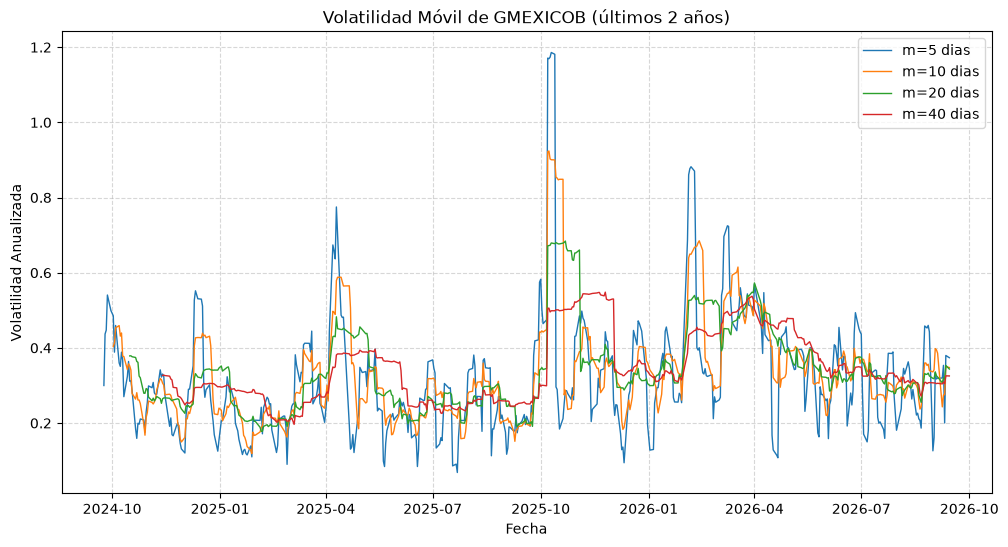

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

for m in ventanas:
    vol_anual = np.sqrt(sigma2[f'var_m{m}'] * 252)
    ax.plot(sigma2.index, vol_anual, label=f'm={m} dias', linewidth=1)

ax.set_xlabel('Fecha')
ax.set_ylabel('Volatilidad Anualizada')
ax.set_title('Volatilidad Móvil de GMEXICOB (últimos 2 años)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

save_path = os.path.join("..", "graficas", "mm_volatilidad_movil.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()